<a href="https://colab.research.google.com/github/SubeenJung0228/Problem-Set-1-econ_3916_PS1/blob/main/Econ_3916_PS1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Econ 3916 PS1 — The Cost of Living Brief

**Starter notebook.** The Canvas assignment is the brief: read it first. This
notebook only gives you the structure, one heading per step in the order the
rubric grades them. Every cell that computes something is yours to write.

**Before you start**
1. *File › Save a copy in Drive*, and rename the copy `Econ 3916 PS1`.
2. Write every explanation in a **text cell**, not in `#` comments. A client
   reads this as a document.
3. **AI is not allowed in Phases 1–3.** You write the dictionaries, the loops,
   the data fetches and the interpretation yourself. Phase 4 is where AI is
   required.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

---
## Phase 1: Construct the Basket (30 pts)

### Step 1.1: Define the household (20 pts)

**Who is the household?** Describe one concrete household in a sentence or two:
who earns, how they get to work, what they spend on. Every later choice has to
be defensible for them.

*Your answer here.*

The household is a low-to-middle-income family living in Orlando, FL, consisting of two working parents and one school-aged child. One parent works full-time as a retail store employee, while the other works as a nursing assistant at a local healthcare facility. They earn hourly wages and commute by public transportation to avoid the high costs of owning and maintaining a car. Their largest expenses are rent, groceries, transportation, utilities, childcare, and healthcare.

> ### New idiom — a list of dictionaries
>
> A **dictionary** holds values under names: `{"Item": "Rent", "weight": 0.35}`.
> `item["weight"]` reads a value back by its name.
>
> A **list of dictionaries** is one dictionary per row, in square brackets and
> separated by commas. It is how you store a small table by hand:
>
> ```python
> fruit = [
>     {"name": "apple",  "price": 0.50},
>     {"name": "banana", "price": 0.25},
> ]
> for f in fruit:            # f is one dictionary at a time
>     print(f["name"], f["price"])
> ```
>
> Use the keys `Item`, `Price_2019`, `Price_2024` and `weight`: the Phase 4
> prompt assumes those names.

In [2]:
# At least six categories. Weights are shares of monthly spending and must sum to 1.0.
household_basket = [
    {"Item": "Rent", "Price_2019": 1750, "Price_2024": 2100, "weight": 0.48},
    {"Item": "Groceries", "Price_2019": 620, "Price_2024": 750, "weight": 0.17},
    {"Item": "Utilities", "Price_2019": 160, "Price_2024": 200, "weight": 0.05},
    {"Item": "Public_transportation", "Price_2019": 380, "Price_2024": 450, "weight": 0.1},
    {"Item": "Childcare", "Price_2019": 320, "Price_2024": 400, "weight": 0.09},
    {"Item": "Healthcare", "Price_2019": 290, "Price_2024": 350, "weight": 0.08},
    {"Item": "Personal_care", "Price_2019": 130, "Price_2024": 150, "weight": 0.03}

]

In [3]:
# Check: run this after filling in the basket
total_weight = sum(item["weight"] for item in household_basket)
print(f"{len(household_basket)} categories, weights sum to {total_weight:.4f}")

7 categories, weights sum to 1.0000


### Step 1.2: Build the index by hand (10 pts)

> ### New idiom — writing a function
>
> ```python
> def price_change(old, new):
>     """Percentage change from old to new."""
>     return (new - old) / old * 100
>
> price_change(2.00, 2.50)     # 25.0
> ```
>
> `def` names the function and its **parameters** (`old`, `new`). The body is
> indented. `return` hands the result back; without it the function gives back
> `None`. Inside the body, use the parameters, never the names of your own
> variables outside it, or the function only works on one dataset.

In [4]:
def laspeyres(basket, base_key, current_key):
    """Base-weighted price index for `basket`, with the base period = 100."""
    return sum(item["weight"] * item[current_key] / item[base_key] for item in basket) * 100

In [5]:
# 1. the unweighted average price change across categories
changes = []
for item in household_basket:
    change = (item["Price_2024"] - item["Price_2019"]) / item["Price_2019"] * 100
    changes.append(change)
unweighted = sum(changes) / len(changes)
print("Unweighted average change:", round(unweighted, 2), "%")

# 2. your weighted Laspeyres index
# laspeyres(household_basket, "Price_2019", "Price_2024")
index = laspeyres(household_basket, "Price_2019", "Price_2024")
print("Laspeyres index:", round(index, 2))

# 3. the gap between them
gap = (index - 100) - unweighted
print("Gap:", round(gap, 2), "percentage points")

Unweighted average change: 20.78 %
Laspeyres index: 120.62
Gap: -0.16 percentage points


**Why do the two differ, and which would you defend to the client?**

*Your answer here.*

The unweighted average shows a 20.78% increase, while the Laspeyres index shows a 20.62% increase. The difference is small because the Laspeyres index gives each category a weight based on how much the household spends on it. Rent makes up about 48% of the budget and increased by 20%, which is slightly below the unweighted average. Utilities and childcare had larger increases, but they make up a smaller part of the budget, so they have less impact on the result. I would use the Laspeyres index because it better reflects the household’s actual spending. However, it assumes the household keeps buying the same goods and services even when prices change, which could slightly overestimate the actual increase in the cost of living.

---
## Phase 2: Bring in the Official Series (25 pts)

### Step 2.1: Find honest proxies (15 pts)

Fetch at least these four from FRED, plus any your household needs. Lab 2
showed how to read a FRED series from its CSV link, with no API key.

In [6]:
series_ids = ["CPIAUCSL", "CUSR0000SEHA", "CUSR0000SAF11", "CUSR0000SETA02"]

In [7]:
# FRED loader from Lab 2 Step 0 (no API key needed)
def load_fred(series_id, start="1947-01-01", end=None):
    url = (f"https://fred.stlouisfed.org/graph/fredgraph.csv?"
           f"id={series_id}&cosd={start}")
    if end is not None:
        url += f"&coed={end}"
    frame = pd.read_csv(url)
    frame.columns = ["date", series_id]
    frame["date"] = pd.to_datetime(frame["date"])
    frame[series_id] = pd.to_numeric(frame[series_id], errors="coerce")
    return frame.set_index("date")[series_id].dropna()

# Load each required series from FRED, starting in 2019
cpi_all  = load_fred("CPIAUCSL", start="2019-01-01")
rent     = load_fred("CUSR0000SEHA", start="2019-01-01")
food     = load_fred("CUSR0000SAF11", start="2019-01-01")
used_car = load_fred("CUSR0000SETA02", start="2019-01-01")

| Series | Why it is a fair proxy for my household | What it fails to capture |
|---|---|---|
| `CPIAUCSL` | It covers every spending category, so it is the standard benchmark for overall cost of living. | It uses national average weights, while my household spends 48% on rent and owns no car.|
| `CUSR0000SEHA` | Rent is my household's largest category at 48% of spending, so this is the most important proxy. |  It is a national average that includes existing leases, so it misses my city's rents and lags market rents by 12 to 18 months. |
| `CUSR0000SAF11` | Groceries are 17% of my budget, and "food at home" is exactly grocery spending. | It prices a national average food basket, not the specific items and stores my household buys from.|
| `CUSR0000SETA02` | It is required as a benchmark, but it is a weak proxy because my household has no car. | It misses my household's actual transportation cost, which is public transit at 10% of spending.|

### Step 2.2: Put them on the same footing (10 pts)

Rebase every series to 2019 = 100 and plot them on one chart with your
household index. The chart needs axis labels, a legend, and a title that states
a finding rather than naming the variables.

In [8]:
# Rebase to 2019 = 100
def rebase_2019(series):
    """Rescale a series so that its 2019 average equals 100."""
    base_2019 = series.loc[series.index.year == 2019].mean()
    return series / base_2019 * 100

cpi_all_r  = rebase_2019(cpi_all)
rent_r     = rebase_2019(rent)
food_r     = rebase_2019(food)
used_car_r = rebase_2019(used_car)

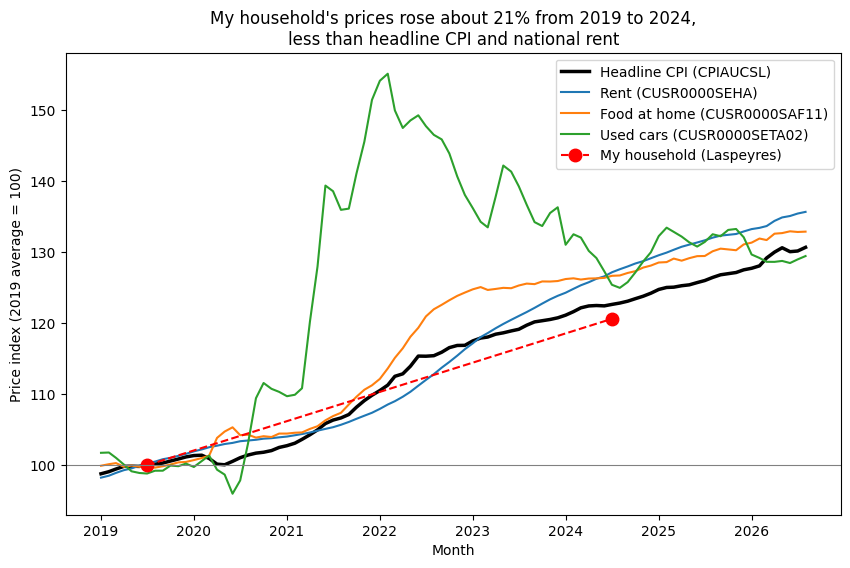

In [9]:
# One chart: every rebased series, plus your household index
household_index = laspeyres(household_basket, "Price_2019", "Price_2024")
household_dates = pd.to_datetime(["2019-07-01", "2024-07-01"])

plt.figure(figsize=(10, 6))
plt.plot(cpi_all_r,  label="Headline CPI (CPIAUCSL)", color="black", linewidth=2.5)
plt.plot(rent_r,     label="Rent (CUSR0000SEHA)")
plt.plot(food_r,     label="Food at home (CUSR0000SAF11)")
plt.plot(used_car_r, label="Used cars (CUSR0000SETA02)")
plt.plot(household_dates, [100, household_index], label="My household (Laspeyres)",
         marker="o", markersize=9, linestyle="--", color="red")

plt.axhline(100, color="gray", linewidth=0.8)
plt.xlabel("Month")
plt.ylabel("Price index (2019 average = 100)")
plt.title("My household's prices rose about 21% from 2019 to 2024,\nless than headline CPI and national rent")
plt.legend()
plt.show()

---
## Phase 3: What the Series Will and Will Not Let You Compare (20 pts)

### Step 3.1: Audit before you analyse (6 pts)

> ### A tool you have not used yet — a regular monthly grid
>
> `s.asfreq("MS")` puts a date-indexed series on one row per month (`"MS"` =
> month start). Any month the series skipped appears as a missing value, so
> `s.asfreq("MS").isna().sum()` counts the gaps. Report the count whatever it
> is; if it is not zero, list the missing months.

In [10]:
# First observation, last observation, frequency and missing months, for every series
cpi_all_full  = load_fred("CPIAUCSL", start="1900-01-01")
rent_full     = load_fred("CUSR0000SEHA", start="1900-01-01")
food_full     = load_fred("CUSR0000SAF11", start="1900-01-01")
used_car_full = load_fred("CUSR0000SETA02", start="1900-01-01")

def audit(name, series):
    """Print the first and last dates and any missing months of a monthly series."""
    grid = series.asfreq("MS")
    missing = grid[grid.isna()].index
    print(name)
    print("  First:", series.index.min().date())
    print("  Last: ", series.index.max().date())
    print("  Missing months:", grid.isna().sum(), list(missing.strftime("%Y-%m")))

audit("CPIAUCSL", cpi_all_full)
audit("CUSR0000SEHA", rent_full)
audit("CUSR0000SAF11", food_full)
audit("CUSR0000SETA02", used_car_full)

CPIAUCSL
  First: 1947-01-01
  Last:  2026-08-01
  Missing months: 1 ['2025-10']
CUSR0000SEHA
  First: 1981-01-01
  Last:  2026-08-01
  Missing months: 1 ['2025-10']
CUSR0000SAF11
  First: 1952-01-01
  Last:  2026-08-01
  Missing months: 1 ['2025-10']
CUSR0000SETA02
  First: 1953-01-01
  Last:  2026-08-01
  Missing months: 0 []


| Series | First | Last | Frequency | Missing months |
|---|---|---|---|---|
| `CPIAUCSL` | 1947-01 | 2026-08 | Monthly | 1 (2025-10) |
| `CUSR0000SEHA` | 1981-01 | 2026-08 | Monthly | 1 (2025-10) |
| `CUSR0000SAF11` | 1952-01 | 2026-08 | Monthly | 1 (2025-10) |
| `CUSR0000SETA02` | 1953-01 | 2026-08 | Monthly | 0 |

**Why October 2025 is missing:** The BLS could not collect CPI data that month because of the federal government shutdown.

### Step 3.2: The sample you actually have (8 pts)

Report three numbers: when the common sample starts, how many months long it
is, and how many months of your longest series it discards. Then compute your
headline comparison twice: over each series' full history, and over the common
sample only.

In [11]:
# Start dates side by side, and the common sample
print("CPIAUCSL starts:      ", cpi_all_full.index.min().date(), "|", len(cpi_all_full), "months")
print("CUSR0000SEHA starts:  ", rent_full.index.min().date(), "|", len(rent_full), "months")
print("CUSR0000SAF11 starts: ", food_full.index.min().date(), "|", len(food_full), "months")
print("CUSR0000SETA02 starts:", used_car_full.index.min().date(), "|", len(used_car_full), "months")

common = pd.DataFrame({"CPIAUCSL": cpi_all_full, "CUSR0000SEHA": rent_full,
                       "CUSR0000SAF11": food_full, "CUSR0000SETA02": used_car_full}).dropna()

longest = max(len(cpi_all_full), len(rent_full), len(food_full), len(used_car_full))

print("\nCommon sample starts:", common.index.min().date())
print("Common sample length:", len(common), "months")
print("Months of the longest series discarded:", longest - len(common))


CPIAUCSL starts:       1947-01-01 | 955 months
CUSR0000SEHA starts:   1981-01-01 | 547 months
CUSR0000SAF11 starts:  1952-01-01 | 895 months
CUSR0000SETA02 starts: 1953-01-01 | 884 months

Common sample starts: 1981-01-01
Common sample length: 547 months
Months of the longest series discarded: 408


In [12]:
# Headline comparison: full history vs common sample
def annual_growth(series):
    """Average yearly percentage change from the first to the last observation."""
    years = (series.index[-1] - series.index[0]).days / 365.25
    return ((series.iloc[-1] / series.iloc[0]) ** (1 / years) - 1) * 100

print("Average yearly price growth (%)")
print("                  Full history   Common sample")
print("CPIAUCSL:      ", round(annual_growth(cpi_all_full), 2), "        ", round(annual_growth(common["CPIAUCSL"]), 2))
print("CUSR0000SEHA:  ", round(annual_growth(rent_full), 2), "        ", round(annual_growth(common["CUSR0000SEHA"]), 2))
print("CUSR0000SAF11: ", round(annual_growth(food_full), 2), "        ", round(annual_growth(common["CUSR0000SAF11"]), 2))
print("CUSR0000SETA02:", round(annual_growth(used_car_full), 2), "        ", round(annual_growth(common["CUSR0000SETA02"]), 2))

Average yearly price growth (%)
                  Full history   Common sample
CPIAUCSL:       3.51          2.99
CUSR0000SEHA:   3.73          3.73
CUSR0000SAF11:  3.18          2.75
CUSR0000SETA02: 2.53          2.1


**What restricting to the common sample assumes, and what not restricting assumes:**

*Your answer here.*

Rent grew faster than headline CPI by 0.22 percentage points using each series’ full history. But starting both series in 1981, the difference is 0.74 points, because CPI includes the high inflation of the 1970s. I would use the common-sample result because it compares both series over the same period.

Restricting the sample assumes the earlier 408 months (1947–1980) are not necessary for understanding price growth today.

Not restricting the sample assumes growth rates from different time periods can be compared fairly.

### Step 3.3: Somebody already made a decision for you (6 pts)

Pull the unadjusted twin of one series (`CPIAUCNS`, `CUUR0000SEHA`,
`CUUR0000SAF11` or `CUUR0000SETA02`) and plot the pair over the last five years.

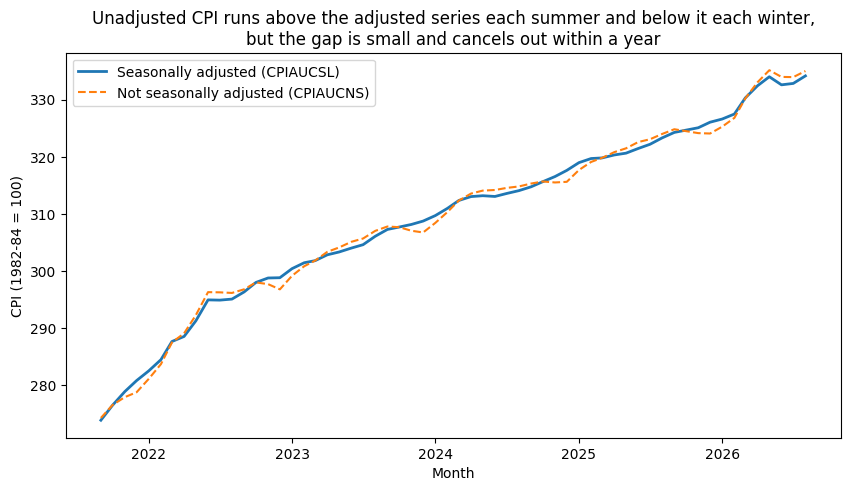

In [13]:
# Seasonally adjusted vs unadjusted, last five years
cpi_nsa = load_fred("CPIAUCNS", start="2021-09-01")
cpi_sa  = cpi_all_full.loc["2021-09-01":]

plt.figure(figsize=(10, 5))
plt.plot(cpi_sa,  label="Seasonally adjusted (CPIAUCSL)", linewidth=2)
plt.plot(cpi_nsa, label="Not seasonally adjusted (CPIAUCNS)", linestyle="--")
plt.xlabel("Month")
plt.ylabel("CPI (1982-84 = 100)")
plt.title("Unadjusted CPI runs above the adjusted series each summer and below it each winter,\nbut the gap is small and cancels out within a year")
plt.legend()
plt.show()

In [14]:
# Numbers quoted in the 4.2 finding: 2019 vs 2024 annual averages
print("Household (Laspeyres):", round(laspeyres(household_basket, "Price_2019", "Price_2024") - 100, 1), "%")
print("Headline CPI:         ", round((cpi_all.loc["2024"].mean() / cpi_all.loc["2019"].mean() - 1) * 100, 1), "%")
print("National rent:        ", round((rent.loc["2024"].mean() / rent.loc["2019"].mean() - 1) * 100, 1), "%")

Household (Laspeyres): 20.6 %
Headline CPI:          22.7 %
National rent:         26.9 %


In [15]:
nsa = load_fred("CPIAUCNS", start="2019-01-01")
print("SA change: ", cpi_all_full.loc["2024"].mean() / cpi_all_full.loc["2019"].mean() - 1)
print("NSA change:", nsa.loc["2024"].mean() / nsa.loc["2019"].mean() - 1)

SA change:  0.22704868684096335
NSA change: 0.22698898167436954


**What does the gap between the two lines consist of? Which series belongs in this brief, and why?**

*Your answer here.*

The gap between the two lines comes from seasonal changes that the BLS estimates and removes. Prices often rise in the summer and fall around the winter holidays, and this pattern repeats every year. The adjusted series removes these seasonal changes using a statistical model. So the gap is not fake data, but the part of price changes related to the time of year. I would use the seasonally adjusted series in the brief because the chart in Step 2.2 shows monthly changes, and seasonal ups and downs could make the price trend harder to see. However, for the overall increase, it does not make a difference. I compared the yearly averages for 2019 and 2024, and both series show a 22.7% increase. The unadjusted series would be more useful if the client were setting a payment for a specific month, such as a cost-of-living raise in December, because workers pay actual prices. The BLS also recommends unadjusted data for escalation contracts.

---
## Phase 4: AI Expansion (25 pts)

AI is now allowed and required.

### Task 4.1: The sensitivity surface (15 pts)

Run the P.R.I.M.E. prompt from the brief, then paste the code below and run it.

Baseline index with your weights: 120.62

Contribution to the increase (index points):
Rent                     9.60
Groceries                3.56
Childcare                2.25
Public_transportation    1.84
Healthcare               1.66
Utilities                1.25
Personal_care            0.46
Dominant category: Rent (9.60 of 20.62 points)

Index range across the 0-0.5 sweep (points):
Personal_care            2.70
Childcare                2.40
Utilities                2.30
Public_transportation    1.22
Rent                     0.60
Groceries                0.21
Healthcare               0.04


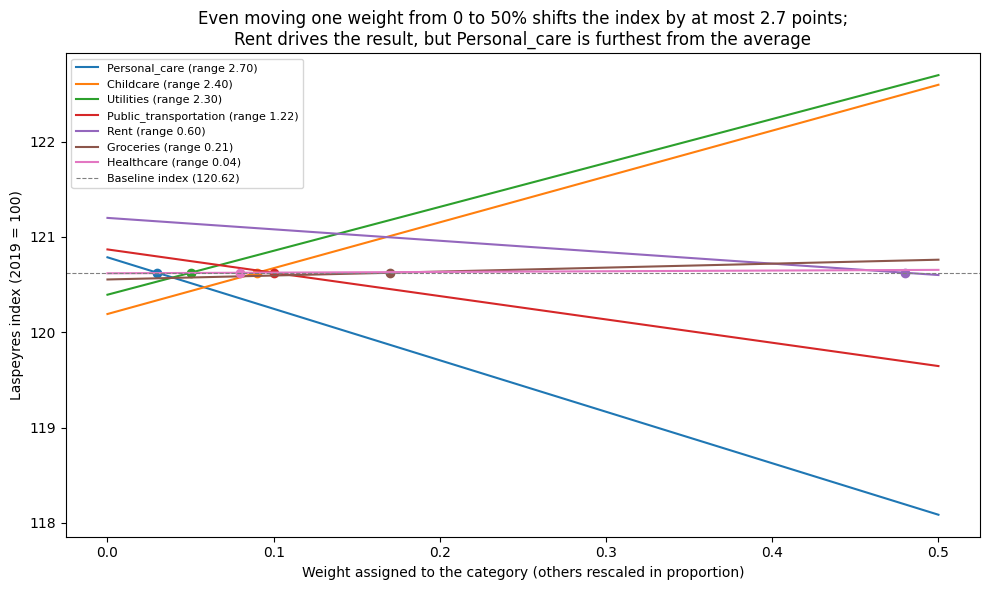

In [16]:
# Paste the AI's code here, run it, and correct it where it is wrong

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ---------------------------------------------------------------
# Laspeyres index for a given vector of weights
# ---------------------------------------------------------------
def laspeyres_from_weights(basket, weights, base_key="Price_2019", current_key="Price_2024"):
    """Weighted Laspeyres index (base period = 100) using the supplied weights."""
    ratios = np.array([item[current_key] / item[base_key] for item in basket])
    return float(np.sum(weights * ratios) * 100)

items = [item["Item"] for item in household_basket]
base_weights = np.array([item["weight"] for item in household_basket])
assert np.isclose(base_weights.sum(), 1.0), "Weights must sum to 1 before the sweep"

baseline = laspeyres_from_weights(household_basket, base_weights)
print(f"Baseline index with your weights: {baseline:.2f}")

ratios = np.array([item["Price_2024"] / item["Price_2019"] for item in household_basket])
contribution = pd.Series(100 * base_weights * (ratios - 1), index=items).sort_values(ascending=False)
print("\nContribution to the increase (index points):")
print(contribution.round(2).to_string())
print(f"Dominant category: {contribution.index[0]} "
      f"({contribution.iloc[0]:.2f} of {baseline - 100:.2f} points)")

# ---------------------------------------------------------------
# Sweep each category's weight from 0 to 0.5
# ---------------------------------------------------------------
# WHY RENORMALISE: the weights are budget shares, so they must sum to 1.
# If we raised one category's weight without shrinking the others, the
# total would exceed 1 and the index would rise mechanically (roughly
# 1.2 points for every extra 0.01 of weight), even if that category's
# prices rose LESS than average. Scaling the other categories by
# (1 - w) while keeping their relative proportions isolates the effect
# of reallocating spending toward one category.
grid = np.linspace(0, 0.5, 51)
results = {}

for k, name in enumerate(items):
    others = base_weights.copy()
    others[k] = 0.0
    others_share = others / others.sum()      # relative proportions of the rest

    curve = []
    for w in grid:
        weights = (1 - w) * others_share
        weights[k] = w
        curve.append(laspeyres_from_weights(household_basket, weights))
    results[name] = curve

sweep = pd.DataFrame(results, index=grid)

# Sensitivity = how far the index moves across the whole 0-0.5 sweep.
# WHAT HIGH SENSITIVITY WOULD MEAN: if the index swung a lot when one
# weight changed, the headline number would depend heavily on getting
# that one budget share right, and a small error in estimating it would
# change the conclusion. Low sensitivity means the result is robust.
spread = (sweep.max() - sweep.min()).sort_values(ascending=False)
print("\nIndex range across the 0-0.5 sweep (points):")
print(spread.round(2).to_string())

# ---------------------------------------------------------------
# One chart
# ---------------------------------------------------------------
fig, ax = plt.subplots(figsize=(10, 6))
for name in spread.index:                    # legend ordered by sensitivity
    line, = ax.plot(sweep.index, sweep[name], label=f"{name} (range {spread[name]:.2f})")
    k = items.index(name)
    ax.plot(base_weights[k], baseline, marker="o", color=line.get_color())

ax.axhline(baseline, color="gray", linestyle="--", linewidth=0.8,
           label=f"Baseline index ({baseline:.2f})")
ax.set_xlabel("Weight assigned to the category (others rescaled in proportion)")
ax.set_ylabel("Laspeyres index (2019 = 100)")
ax.set_title(f"Even moving one weight from 0 to 50% shifts the index by at most "
             f"{spread.max():.1f} points;\n{contribution.index[0]} drives the result, "
             f"but {spread.index[0]} is furthest from the average")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

**What did the model get wrong, or get right in a way you had to check? Show the check.**

*Your answer here.*

The model’s calculation is correct, and I checked it in three ways. First, its baseline (120.6233) matches my laspeyres() function from Phase 1. Second, each curve gives the same index at its category’s actual weight, confirming that the original weights are reproduced. The dots alone do not prove this because the code places them directly on the baseline. Third, my prompt said six categories, but my basket has seven. Since the code reads from household_basket, all seven are included.

However, the model’s claim that a 10-percentage-point error in any weight would change the index by less than 0.5 points is not quite correct. Personal care changes the index by 0.54 points, so I would say the index stays around 120.1 to 121.1.

I also made two changes to the code. I added a contribution table showing that rent accounts for 9.60 of the 20.62-point increase. I also changed the chart title because saying personal care “matters most” is misleading. Its line is steepest because its price change differs most from the average, but increasing its budget share from 3% to 50% is unrealistic. Rent has the biggest impact on the overall result, while personal care is the most sensitive to changes in weight.

In [17]:
# Check: the AI's baseline matches my own laspeyres() function from Phase 1
mine = laspeyres(household_basket, "Price_2019", "Price_2024")
print("My laspeyres():", round(mine, 4), "| AI baseline:", round(baseline, 4))

My laspeyres(): 120.6233 | AI baseline: 120.6233


### AI Transcript

**Model:** Claude Opus 5.5   **Date:** October 8, 2026

*Paste the prompt exactly as you sent it, then the model's reply exactly as it
came back, before your corrections.*

[Prep] Act as an applied economist who builds reproducible analysis for client deliverables.

[Request] I have a household price index built as a weighted Laspeyres over six spending categories, in a list of dicts named household_basket with keys Item, Price_2019, Price_2024 and weight. Write Python that sweeps each category’s weight from 0 to 0.5, holding the others in proportion, recomputes the index, and produces a single chart showing which category’s weight the result is most sensitive to.

[Iterate] numpy, pandas and matplotlib only. Reuse my variable names. No deprecated matplotlib arguments.

[Mechanism Check] Add comments explaining why renormalising the other weights is necessary, and what it would mean if the index were highly sensitive to a single category.

[Evaluate] Tell me which category dominates my result and what I should say to a client about it.


```python

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ---------------------------------------------------------------
# Laspeyres index for a given vector of weights
# ---------------------------------------------------------------
def laspeyres_from_weights(basket, weights, base_key="Price_2019", current_key="Price_2024"):
    """Weighted Laspeyres index (base period = 100) using the supplied weights."""
    ratios = np.array([item[current_key] / item[base_key] for item in basket])
    return float(np.sum(weights * ratios) * 100)

items = [item["Item"] for item in household_basket]
base_weights = np.array([item["weight"] for item in household_basket])
assert np.isclose(base_weights.sum(), 1.0), "Weights must sum to 1 before the sweep"

baseline = laspeyres_from_weights(household_basket, base_weights)
print(f"Baseline index with your weights: {baseline:.2f}")

# ---------------------------------------------------------------
# Sweep each category's weight from 0 to 0.5
# ---------------------------------------------------------------
# WHY RENORMALISE: the weights are budget shares, so they must sum to 1.
# If we raised one category's weight without shrinking the others, the
# total would exceed 1 and the index would rise mechanically (roughly
# 1.2 points for every extra 0.01 of weight), even if that category's
# prices rose LESS than average. Scaling the other categories by
# (1 - w) while keeping their relative proportions isolates the effect
# of reallocating spending toward one category.
grid = np.linspace(0, 0.5, 51)
results = {}

for k, name in enumerate(items):
    others = base_weights.copy()
    others[k] = 0.0
    others_share = others / others.sum()      # relative proportions of the rest

    curve = []
    for w in grid:
        weights = (1 - w) * others_share
        weights[k] = w
        curve.append(laspeyres_from_weights(household_basket, weights))
    results[name] = curve

sweep = pd.DataFrame(results, index=grid)

# Sensitivity = how far the index moves across the whole 0-0.5 sweep.
# WHAT HIGH SENSITIVITY WOULD MEAN: if the index swung a lot when one
# weight changed, the headline number would depend heavily on getting
# that one budget share right, and a small error in estimating it would
# change the conclusion. Low sensitivity means the result is robust.
spread = (sweep.max() - sweep.min()).sort_values(ascending=False)
print("\nIndex range across the 0-0.5 sweep (points):")
print(spread.round(2).to_string())

# ---------------------------------------------------------------
# One chart
# ---------------------------------------------------------------
fig, ax = plt.subplots(figsize=(10, 6))
for name in spread.index:                    # legend ordered by sensitivity
    line, = ax.plot(sweep.index, sweep[name], label=f"{name} (range {spread[name]:.2f})")
    k = items.index(name)
    ax.plot(base_weights[k], baseline, marker="o", color=line.get_color())

ax.axhline(baseline, color="gray", linestyle="--", linewidth=0.8,
           label=f"Baseline index ({baseline:.2f})")
ax.set_xlabel("Weight assigned to the category (others rescaled in proportion)")
ax.set_ylabel("Laspeyres index (2019 = 100)")
ax.set_title(f"No single weight moves the index by more than {spread.max():.1f} points; "
             f"{spread.index[0]} matters most per unit of weight")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()
```

**Which category dominates your result**
Rent dominates. The index is 120.62. Rent contributes 9.6 of the 20.62 points of increase (0.48 × 20%), nearly half. Groceries come next at about 3.6 points.
Rent is not, however, what the index is most sensitive to. Rent rose 20%, close to the average of the other categories (about 21.2%), so its range across the sweep is only 0.60 points. The largest ranges belong to personal care (2.70), childcare (2.40) and utilities (2.30), the categories furthest from the average. Within a realistic ±10 percentage points of their actual weights, none of them moves the index by more than about half a point.

**What to say to the client**
“This household’s cost of living rose about 21% between 2019 and 2024. Rent is the main driver, accounting for nearly half of the increase because it takes almost half the budget. The result is robust to how we estimated spending shares: even if any one category’s share were off by 10 percentage points, the index would change by less than half a point. The main caveat is that the index assumes the household kept buying the same basket, so if they cut back on items that became more expensive, their true increase may be slightly lower.”

### Task 4.2: The written finding (10 pts)

250 words at most, to the director. A number in the first sentence, no code,
and a confidence level.

*Your finding here.*

Director,

This household’s cost of living increased by about 21% from 2019 to 2024. In other words, something that cost \$100 in 2019 would cost about \$121 in 2024.

Rent had the biggest impact because it makes up almost half of the household’s budget and increased by 20%. Childcare and utilities increased the most, at 25% each, but they account for a much smaller share of spending.

The increase is slightly lower than the national figures, which show an increase of about 23% for overall prices and 27% for rent. This is mainly because the household’s rent increased less than the national average. National figures also include expenses like cars and gas, which are not part of this household’s budget.

I have high confidence that the true increase is close to 21%. Even if any one spending share were off by 10 percentage points, the index would stay between about 120.1 and 121.1. Only an extreme shift, such as moving one category to half the budget, would push it to 118–123. However, the calculation assumes the household buys the same things as before. If they spend less on items that have become more expensive, their actual cost increase could be smaller. Also, October 2025 data is missing because of the government shutdown, but this does not affect the comparison.

Overall, the household’s cost of living increased by about 21% since 2019, mainly due to rent. I am confident that this is a reasonable estimate.

---
### Before you submit
- [ ] Every step above has output, and every explanation is in a text cell
- [ ] The AI Transcript names the model and the date
- [ ] *Runtime › Restart and run all* runs without errors
- [ ] Share link on Canvas; the same notebook in `Problem Set 1/` on GitHub